##  DATA CLEANING & DATA SPLITTING (RT-IoT2022)
**Mục tiêu:** Tạo bộ dữ liệu sạch và 3 tập Train (70%), Validation (15%), Test (15%) phục vụ cùng hai baseline Random Forest và MLP.

**Nguyên tắc:** Chỉ làm sạch dữ liệu, không chuẩn hóa, không One-Hot Encoding.



In [24]:
from pathlib import Path
import json
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from IPython.display import display
SRC = Path(
    r"C:\Users\hauth\OneDrive\Tài liệu\GitHub"
    r"\SGU26K2_MayHoc_DCT124C3_Nhom4_RT-IoT2022"
    r"\final_IoT\sample_project\raw data\RT_IOT2022.csv"
)
# Tìm thư mục gốc để notebook chạy đúng khi mở từ notebooks hoặc từ project root.
ROOT = Path.cwd().resolve()
ROOT = ROOT.parent if ROOT.name == 'notebooks' else ROOT
DATA = ROOT / 'data'
RAW = DATA / 'raw'
OUT = DATA / 'processed'
TABLES = ROOT / 'reports' / 'data_cleaning_splitting' / 'tables'
FIGURES = ROOT / 'reports' / 'data_cleaning_splitting' / 'figures'
RESULTS = ROOT / 'results'
for folder in [RAW, OUT, TABLES, FIGURES, RESULTS]:
    folder.mkdir(parents=True, exist_ok=True)
SRC = RAW / 'RT_IOT2022.csv'


print('Thư mục xuất kết quả:', ROOT)

Thư mục xuất kết quả: C:\Users\hauth\OneDrive\Tài liệu\GitHub\SGU26K2_MayHoc_DCT124C3_Nhom4_RT-IoT2022\final_IoT\sample_project\result\preprocessing\preprocessing_basic


### 1. Đọc và kiểm tra dữ liệu đầu vào
Đọc dữ liệu gốc, xác định target và các cột không được dùng làm đặc trưng. Việc kiểm tra ở đây là quan sát.

In [13]:
if not SRC.is_file():
    source_candidates = []
    filenames = ('RT_IOT2022.csv', 'RT_IoT2022.csv')

    for base in [ROOT, *ROOT.parents]:
        for filename in filenames:
            candidates = [
                base / 'raw data' / filename,
                base / 'data' / 'raw' / filename,
            ]
            source_candidates.extend(
                path for path in candidates if path.is_file()
            )

    # Remove duplicate paths while preserving order.
    source_candidates = list(dict.fromkeys(source_candidates))

    if not source_candidates:
        raise FileNotFoundError(
            'Không tìm thấy RT_IOT2022.csv. '
            f'Đã tìm trong các thư mục cha của: {ROOT}'
        )

    SRC = source_candidates[0]

df = pd.read_csv(SRC, low_memory=False)

TARGET = 'Attack_type'
EXPORT_INDEX = 'Unnamed: 0'
CONSTANT = 'bwd_URG_flag_count'

assert TARGET in df.columns
assert df[TARGET].notna().all()

with SRC.open('rb') as file:
    raw_sha256 = hashlib.file_digest(file, 'sha256').hexdigest()

raw_counts = df[TARGET].value_counts().sort_index()

print('File dữ liệu:', SRC)
print('Kích thước dữ liệu gốc:', df.shape)
print('Số lớp nhãn:', df[TARGET].nunique())
print('Số ô thiếu:', int(df.isna().sum().sum()))
print('SHA-256:', raw_sha256)

display(raw_counts.rename('Số mẫu gốc').to_frame())

File dữ liệu: C:\Users\hauth\OneDrive\Tài liệu\GitHub\SGU26K2_MayHoc_DCT124C3_Nhom4_RT-IoT2022\final_IoT\sample_project\result\preprocessing\raw data\RT_IOT2022.csv
Kích thước dữ liệu gốc: (123117, 85)
Số lớp nhãn: 12
Số ô thiếu: 0
SHA-256: 956956c09c1764584fa08acd0f6876475626bcedcd6a6b1f8c492c2e9a2089ea


,Số mẫu gốc
Attack_type,
ARP_poisioning,7750
DDOS_Slowloris,534
DOS_SYN_Hping,94659
MQTT_Publish,4146
Metasploit_Brute_Force_SSH,37
NMAP_FIN_SCAN,28
NMAP_OS_DETECTION,2000
NMAP_TCP_scan,1002
NMAP_UDP_SCAN,2590


### 2. Loại cột không mang thông tin dự đoán
Loại Unnamed: 0 vì là chỉ số xuất CSV, loại bwd_URG_flag_count vì có một giá trị duy nhất. Không xóa các đặc trưng có tương quan cao chỉ dựa trên EDA.

In [14]:
removed_columns = []
if EXPORT_INDEX in df.columns:
    removed_columns.append(EXPORT_INDEX)
if CONSTANT in df.columns and df[CONSTANT].nunique(dropna=False) == 1:
    removed_columns.append(CONSTANT)
work = df.drop(columns=removed_columns).copy()
print('Các cột đã loại:', removed_columns)
print('Kích thước sau loại cột:', work.shape)
removed_table = pd.DataFrame({'removed_column': removed_columns, 'reason': ['CSV export index' if x == EXPORT_INDEX else 'Constant feature' for x in removed_columns]})
removed_table.to_csv(TABLES / '01_removed_columns.csv', index=False)
display(removed_table)

Các cột đã loại: ['Unnamed: 0', 'bwd_URG_flag_count']
Kích thước sau loại cột: (123117, 83)


,removed_column,reason
0,Unnamed: 0,CSV export index
1,bwd_URG_flag_count,Constant feature


### 3. Kiểm tra dữ liệu không hữu hạn
Chỉ xử lý inf/-inf nếu có, thay bằng NaN để ghi nhận. Nếu phát sinh NaN trong tương lai, không điền bằng trung bình của toàn dataset.

In [15]:
numeric_cols = work.select_dtypes(include=[np.number]).columns.tolist()
# Chuyển vô cực thành NaN để bước kiểm tra thiếu dữ liệu xử lý thống nhất.
inf_mask = np.isinf(work[numeric_cols].to_numpy(dtype='float64'))
inf_count = int(inf_mask.sum())
if inf_count > 0:
    work[numeric_cols] = work[numeric_cols].replace([np.inf, -np.inf], np.nan)
missing_by_col = work.isna().sum().rename('missing_count').to_frame()
missing_by_col.to_csv(TABLES / '02_missing_by_column.csv')
print('Số ô vô cực được phát hiện:', inf_count)
print('Tổng số ô NaN sau kiểm tra:', int(work.isna().sum().sum()))
display(missing_by_col[missing_by_col['missing_count'] > 0])

Số ô vô cực được phát hiện: 0
Tổng số ô NaN sau kiểm tra: 0


,missing_count


### 4. Xóa bản ghi trùng hoàn toàn
Hai dòng trùng toàn bộ đặc trưng và nhãn được giữ lại một dòng. Cột chỉ số đã loại nên không che khuất bản ghi trùng.

In [16]:
rows_before_dedup = len(work)
exact_duplicates = int(work.duplicated(keep='first').sum())
work = work.drop_duplicates(keep='first').reset_index(drop=True)
rows_after_dedup = len(work)
print('Bản ghi trùng hoàn toàn đã loại:', exact_duplicates)
print('Số bản ghi còn lại:', rows_after_dedup)
assert work.duplicated().sum() == 0

Bản ghi trùng hoàn toàn đã loại: 5195
Số bản ghi còn lại: 117922


### 5. Phát hiện và xử lý xung đột nhãn
Nếu có cùng toàn bộ vector đặc trưng nhưng khác Attack_type, loại toàn bộ các dòng thuộc nhóm mâu thuẫn, không tự chọn nhãn theo đa số. Điều này tránh tình trạng cùng một đầu vào xuất hiện ở các tập với hai nhãn khác nhau. Đổi lại, một lượng nhỏ dữ liệu bị loại.

In [17]:
features = [c for c in work.columns if c != TARGET]
# Hash các đặc trưng để lọc nhanh ứng viên có cùng đầu vào nhưng khác nhãn.
feature_hash = pd.util.hash_pandas_object(work[features], index=False)
hash_label_counts = pd.DataFrame({'hash': feature_hash, 'label': work[TARGET]}).groupby('hash')['label'].nunique()
conflict_hashes = hash_label_counts[hash_label_counts > 1].index
candidates = work.loc[feature_hash.isin(conflict_hashes)].copy()
if len(candidates) > 0:
    # Xác minh lại bằng toàn bộ đặc trưng, tránh kết luận chỉ dựa trên hash.
    confirmed_counts = candidates.groupby(features, dropna=False, sort=False)[TARGET].transform('nunique')
    confirmed = candidates.loc[confirmed_counts > 1].copy()
else:
    confirmed = candidates.copy()
conflict_rows = len(confirmed)
conflict_groups = confirmed.groupby(features, dropna=False).ngroups if conflict_rows else 0
confirmed.to_csv(TABLES / '03_conflicting_label_rows.csv', index=False)
work = work.drop(index=confirmed.index).reset_index(drop=True)
print('Số nhóm đặc trưng xung đột:', conflict_groups)
print('Số dòng xung đột đã loại:', conflict_rows)
print('Số dòng dữ liệu sạch:', len(work))
assert work[TARGET].notna().all()

Số nhóm đặc trưng xung đột: 6
Số dòng xung đột đã loại: 13
Số dòng dữ liệu sạch: 117909


### 6. Kiểm tra lại tính duy nhất của vector đặc trưng
Nếu không còn xung đột nhãn và không còn dòng trùng hoàn toàn thì mỗi vector đặc trưng là duy nhất. Kiểm tra điều này trước khi chia để giảm nguy cơ rò rỉ mẫu trùng giữa Train, Validation và Test.

In [18]:
remaining_exact_dups = int(work.duplicated().sum())
remaining_feature_dups = int(work.duplicated(subset=features).sum())
print('Trùng hoàn toàn còn lại:', remaining_exact_dups)
print('Trùng vector đặc trưng còn lại:', remaining_feature_dups)
assert remaining_exact_dups == 0
assert remaining_feature_dups == 0

Trùng hoàn toàn còn lại: 0
Trùng vector đặc trưng còn lại: 0


### 7. Chia dữ liệu 70% / 15% / 15% có phân tầng
Chia Train 70% và Temp 30%, sau đó chia Temp thành Validation 15% và Test 15%. stratify giúp giữ tỷ lệ các nhãn tương đối đồng đều. random_state=42 giúp tái lập đúng kết quả khi chạy lại.

In [19]:
class_counts_clean = work[TARGET].value_counts().sort_index()
assert class_counts_clean.min() >= 4
# Chia phân tầng để giữ phân bố 12 lớp tương đối ổn định giữa các tập.
train_df, temp_df = train_test_split(work, test_size=0.30, stratify=work[TARGET], random_state=42, shuffle=True)
val_df, test_df = train_test_split(temp_df, test_size=0.50, stratify=temp_df[TARGET], random_state=42, shuffle=True)
train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)
print('Train:', train_df.shape, f'({len(train_df)/len(work):.2%})')
print('Validation:', val_df.shape, f'({len(val_df)/len(work):.2%})')
print('Test:', test_df.shape, f'({len(test_df)/len(work):.2%})')
assert len(train_df) + len(val_df) + len(test_df) == len(work)

Train: (82536, 83) (70.00%)
Validation: (17686, 83) (15.00%)
Test: (17687, 83) (15.00%)


### 8. Kiểm tra không rò rỉ mẫu trùng giữa các tập
Dùng mã hash trên toàn bộ đặc trưng để so sánh các tập. Vì đã loại bản ghi trùng và xung đột nhãn trước đó, giao giữa các tập phải bằng 0. Đây là kiểm tra rò rỉ do bản ghi trùng, không chứng minh không tồn tại mọi loại rò rỉ khác ví dụ dữ liệu cùng phiên, cùng thiết bị.

In [20]:
def feature_hash_set(frame):
    return set(pd.util.hash_pandas_object(frame[features], index=False).to_numpy())
train_hash = feature_hash_set(train_df)
val_hash = feature_hash_set(val_df)
test_hash = feature_hash_set(test_df)
overlap_tv = len(train_hash & val_hash)
overlap_tt = len(train_hash & test_hash)
overlap_vt = len(val_hash & test_hash)
leakage_check = pd.DataFrame({'pair': ['Train–Validation', 'Train–Test', 'Validation–Test'], 'shared_feature_hashes': [overlap_tv, overlap_tt, overlap_vt]})
leakage_check.to_csv(TABLES / '04_cross_split_overlap.csv', index=False)
display(leakage_check)
assert max(overlap_tv, overlap_tt, overlap_vt) == 0

,pair,shared_feature_hashes
0,Train–Validation,0
1,Train–Test,0
2,Validation–Test,0


### 9. Kiểm tra phân bố nhãn sau chia và lưu bảng
Bảng dưới đây cho thấy số lượng từng lớp trong ba tập. Tất cả 12 lớp phải xuất hiện trong cả Train, Validation và Test. Không dùng oversampling trước khi chia tập.

In [21]:
label_table = pd.DataFrame({'Clean': work[TARGET].value_counts(), 'Train': train_df[TARGET].value_counts(), 'Validation': val_df[TARGET].value_counts(), 'Test': test_df[TARGET].value_counts()}).fillna(0).astype(int).sort_index()
for split_name in ['Clean', 'Train', 'Validation', 'Test']:
    label_table[split_name + '_pct'] = (label_table[split_name] / label_table[split_name].sum() * 100).round(4)
label_table.to_csv(TABLES / '05_class_distribution_by_split.csv', encoding='utf-8-sig')
display(label_table)
assert (label_table[['Train', 'Validation', 'Test']] > 0).all().all()

,Clean,Train,Validation,Test,Clean_pct,Train_pct,Validation_pct,Test_pct
Attack_type,,,,,,,,
ARP_poisioning,7620,5334,1143,1143,6.4626,6.4626,6.4627,6.4624
DDOS_Slowloris,532,373,80,79,0.4512,0.4519,0.4523,0.4467
DOS_SYN_Hping,90089,63062,13513,13514,76.4055,76.4054,76.4051,76.4064
MQTT_Publish,4142,2899,621,622,3.5129,3.5124,3.5113,3.5167
Metasploit_Brute_Force_SSH,35,25,5,5,0.0297,0.0303,0.0283,0.0283
NMAP_FIN_SCAN,28,20,4,4,0.0237,0.0242,0.0226,0.0226
NMAP_OS_DETECTION,2000,1400,300,300,1.6962,1.6962,1.6963,1.6962
NMAP_TCP_scan,1002,701,151,150,0.8498,0.8493,0.8538,0.8481
NMAP_UDP_SCAN,2582,1807,387,388,2.1898,2.1893,2.1882,2.1937


### 10. Biểu đồ trước/sau làm sạch và phân bố ba tập

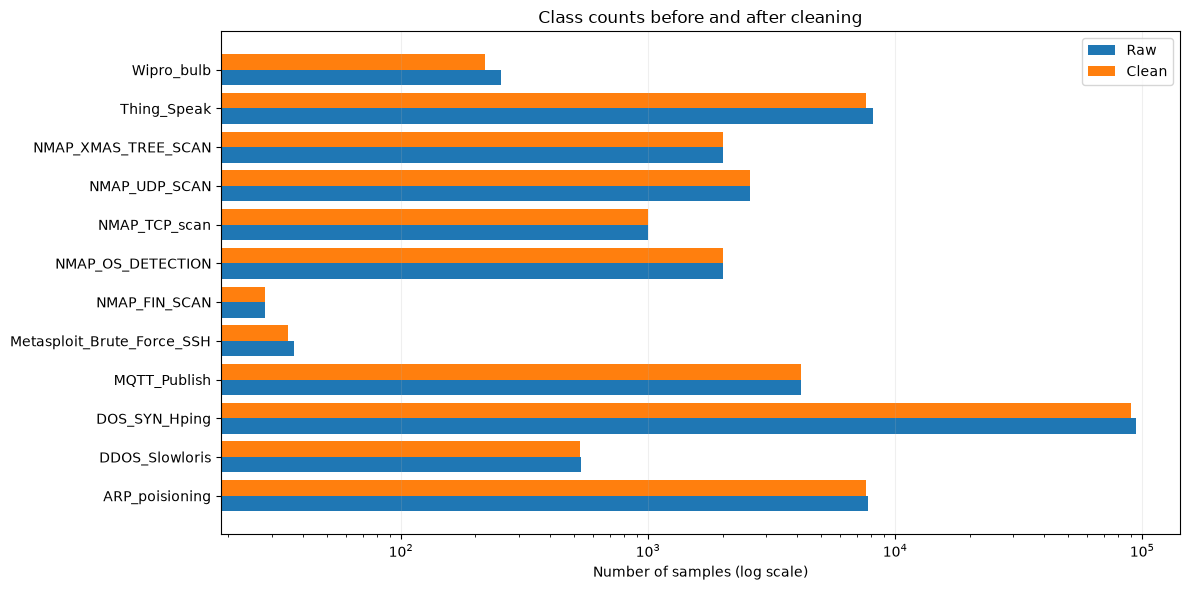

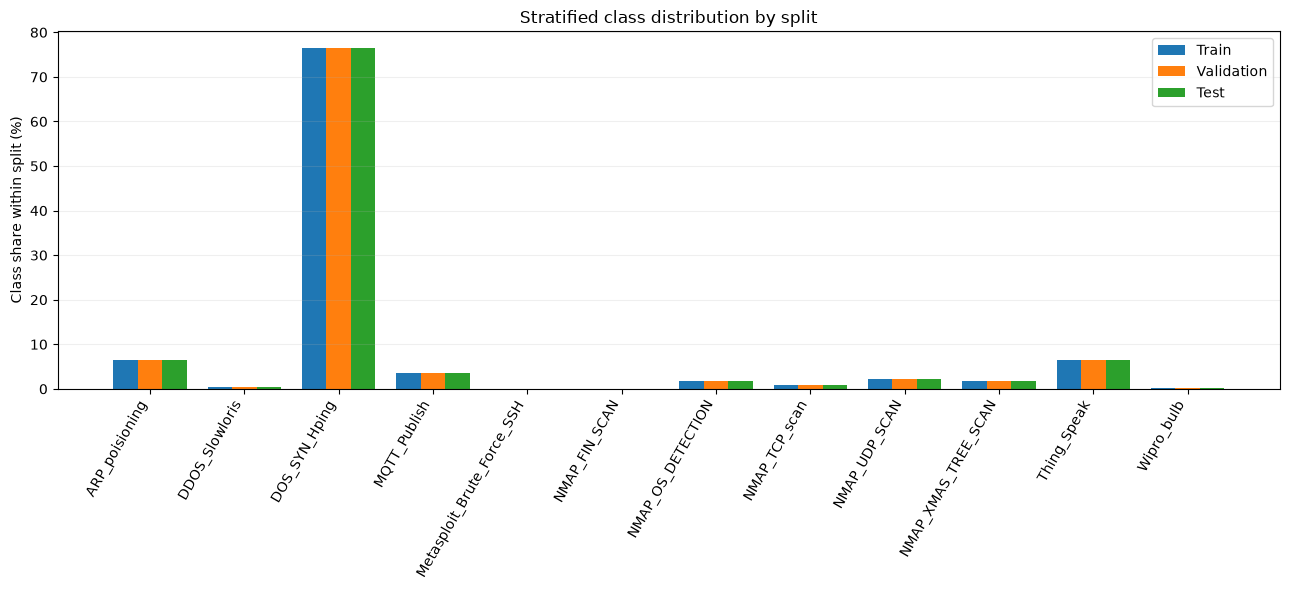

In [22]:
fig, ax = plt.subplots(figsize=(12, 6))
ypos = np.arange(len(raw_counts))
clean_counts = work[TARGET].value_counts().reindex(raw_counts.index, fill_value=0)
ax.barh(ypos - 0.2, raw_counts.values, height=0.4, label='Raw')
ax.barh(ypos + 0.2, clean_counts.values, height=0.4, label='Clean')
ax.set_yticks(ypos, raw_counts.index)
ax.set_xscale('log')
ax.set_xlabel('Number of samples (log scale)')
ax.set_title('Class counts before and after cleaning')
ax.legend()
ax.grid(axis='x', alpha=0.2)
fig.tight_layout()
fig.savefig(FIGURES / '01_before_after_cleaning.png', dpi=160, bbox_inches='tight')
plt.show()
fig, ax = plt.subplots(figsize=(13, 6))
xpos = np.arange(len(label_table))
for i, split_name in enumerate(['Train', 'Validation', 'Test']):
    ax.bar(xpos + (i - 1) * 0.26, label_table[split_name + '_pct'].values, width=0.26, label=split_name)
ax.set_xticks(xpos, label_table.index, rotation=60, ha='right')
ax.set_ylabel('Class share within split (%)')
ax.set_title('Stratified class distribution by split')
ax.legend()
ax.grid(axis='y', alpha=0.2)
fig.tight_layout()
fig.savefig(FIGURES / '02_class_share_by_split.png', dpi=160, bbox_inches='tight')
plt.show()

### 11. Xuất dữ liệu sạch và ba tập chia

In [23]:
work.to_csv(OUT / 'RT_IoT2022_clean.csv', index=False)
train_df.to_csv(OUT / 'train.csv', index=False)
val_df.to_csv(OUT / 'validation.csv', index=False)
test_df.to_csv(OUT / 'test.csv', index=False)
audit = pd.DataFrame([{'stage': 'Raw', 'rows': len(df)}, {'stage': 'After removing exact duplicates', 'rows': rows_after_dedup}, {'stage': 'After removing label conflicts', 'rows': len(work)}, {'stage': 'Train', 'rows': len(train_df)}, {'stage': 'Validation', 'rows': len(val_df)}, {'stage': 'Test', 'rows': len(test_df)}])
audit.to_csv(TABLES / '06_cleaning_audit.csv', index=False)
display(audit)
summary = {'source_file': SRC.name, 'source_sha256': raw_sha256, 'raw_rows': len(df), 'raw_columns': len(df.columns), 'removed_columns': removed_columns, 'exact_duplicate_rows_removed': exact_duplicates, 'conflicting_feature_groups_removed': conflict_groups, 'conflicting_rows_removed': conflict_rows, 'clean_rows': len(work), 'clean_columns': len(work.columns), 'target': TARGET, 'classes': sorted(work[TARGET].unique().tolist()), 'split': {'train': len(train_df), 'validation': len(val_df), 'test': len(test_df), 'random_state': 42, 'stratified': True}, 'cross_split_duplicate_feature_hashes': {'train_validation': overlap_tv, 'train_test': overlap_tt, 'validation_test': overlap_vt}, 'note': 'No imputation, scaling, one-hot encoding, resampling or feature selection performed at Step 2.'}
(RESULTS / 'step2_summary.json').write_text(json.dumps(summary, indent=2, ensure_ascii=False), encoding='utf-8')
print(json.dumps(summary, indent=2, ensure_ascii=False))
print('Đã lưu dữ liệu vào:', OUT)
print('Đã lưu bảng vào:', TABLES)
print('Đã lưu hình vào:', FIGURES)

compressed_files = {
    'train': train_df,
    'validation': val_df,
    'test': test_df,
}

for name, frame in compressed_files.items():
    frame.to_csv(
        OUT / f'{name}.csv.gz',
        index=False,
        compression={'method': 'gzip', 'mtime': 0},
    )

# Niêm phong file test bằng SHA-256 và thông tin bất biến.
test_gz = OUT / 'test.csv.gz'
test_sha256 = hashlib.sha256(test_gz.read_bytes()).hexdigest()
test_seal = {
    'file': test_gz.name,
    'sha256': test_sha256,
    'rows': len(test_df),
    'columns': len(test_df.columns),
    'sealed': True,
}
(OUT / 'test.csv.gz.seal.json').write_text(
    json.dumps(test_seal, indent=2, ensure_ascii=False),
    encoding='utf-8',
)

for name in compressed_files:
    source = OUT / f'{name}.csv.gz'
    destination = RAW / source.name
    destination.write_bytes(source.read_bytes())

print('Đã lưu train/validation/test dạng CSV.GZ vào:', RAW)
print('Đã niêm phong test bằng SHA-256:', test_sha256)

,stage,rows
0,Raw,123117
1,After removing exact duplicates,117922
2,After removing label conflicts,117909
3,Train,82536
4,Validation,17686
5,Test,17687


{
  "source_file": "RT_IOT2022.csv",
  "source_sha256": "956956c09c1764584fa08acd0f6876475626bcedcd6a6b1f8c492c2e9a2089ea",
  "raw_rows": 123117,
  "raw_columns": 85,
  "removed_columns": [
    "Unnamed: 0",
    "bwd_URG_flag_count"
  ],
  "exact_duplicate_rows_removed": 5195,
  "conflicting_feature_groups_removed": 6,
  "conflicting_rows_removed": 13,
  "clean_rows": 117909,
  "clean_columns": 83,
  "target": "Attack_type",
  "classes": [
    "ARP_poisioning",
    "DDOS_Slowloris",
    "DOS_SYN_Hping",
    "MQTT_Publish",
    "Metasploit_Brute_Force_SSH",
    "NMAP_FIN_SCAN",
    "NMAP_OS_DETECTION",
    "NMAP_TCP_scan",
    "NMAP_UDP_SCAN",
    "NMAP_XMAS_TREE_SCAN",
    "Thing_Speak",
    "Wipro_bulb"
  ],
  "split": {
    "train": 82536,
    "validation": 17686,
    "test": 17687,
    "random_state": 42,
    "stratified": true
  },
  "cross_split_duplicate_feature_hashes": {
    "train_validation": 0,
    "train_test": 0,
    "validation_test": 0
  },
  "note": "No imputation, scal

### 12. Kết luận 
- Đã loại cột chỉ số, cột hằng, dòng trùng hoàn toàn và các dòng có đặc trưng giống nhau nhưng nhãn xung đột.
- Đã chia 70/15/15 có phân tầng và kiểm tra không có vector đặc trưng trùng giữa ba tập.
- Chưa xóa outlier theo IQR vì có thể là tín hiệu tấn công.